# Llenado de una carcasa con canal frío: prueba del módulo de inyección de FEM-sim

Este cuaderno simula el **llenado de la carcasa de control** (`CAD de pieza_uppercase`, una cubierta de 60 × 150 × 12.5 mm con aperturas para
botones, de ABS) alimentada por un **canal frío simple**: un bebedero recto y una entrada puntual sobre la cara de la pared lateral. Es la prueba
de lo hecho hasta ahora en el módulo de inyección (`docs/PLAN_INYECCION.md`): piezas desde CAD como **doble superficie** (fase 1), **red de
alimentación** (fase 2) y el llenado **no isotermo** de Hele-Shaw, comparado con las simulaciones de **Cadmould** de la misma pieza.

**De dónde sale la geometría.** El `.SLDPRT` es el formato nativo de SolidWorks y gmsh no lo lee. En la carpeta de simulación de Cadmould hay
la malla de la pieza (`*.cfe`): la **superficie cerrada** del sólido, 22 740 triángulos con su espesor, el mismo modelo *3D-F* que usa Cadmould.
Aquí se lee esa superficie, se comprueba que es cerrada y que encierra 22 040 mm³ (el volumen real de la pieza) y se entrega a `DualDomain`, que
separa las pieles de las caras del borde, mide el espesor con rayos y une cada piel con la opuesta. Cuando se exporte la pieza a STEP,
`DualDomain.from_step(...)` hace lo mismo desde el CAD.

**Qué se compara.** Cadmould simuló esta pieza con entrada puntual lateral y caudal constante (caso `002`: 16.35 cm³/s, ABS AF312F a 215 °C, molde a
58 °C). Con esas mismas condiciones y **sin canal** (caso A) se puede comparar la presión de entrada, la fuerza de cierre y la temperatura del frente.
Después se añade el canal frío (caso B) y se estima el efecto de su capa congelada (caso C).

**Limitaciones (ver el final).** La viscosidad de Cadmould depende además de la presión (D3) y el módulo Hele-Shaw todavía no lo usa; el canal frío
no calcula su propia capa congelada (se estima con la de la cavidad); no hay empaque ni alabeo en este cuaderno.

In [1]:
import time, pickle
from pathlib import Path

import numpy as np
import scipy.sparse as sp
import scipy.sparse.csgraph as csgraph
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.tri import Triangulation
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

from Source.Pre_processing.DualDomain import DualDomain
from Source.Physics.HeleShaw import HeleShawFilling
from Source.Physics.Rheology import CrossWLF
from Source.Physics.Runners import RunnerSystem

# Archivos de Cadmould de esta pieza: la malla (.cfe), la ficha de entrada (.txt) y los resultados (_Result_Summary.txt)
CASE_DIR = Path(r'F:\Documentos\Simulación inyección\Carcasa control\Archivos simulación')
CASE = 'CAD de pieza_uppercase_002'
for ext in ('.cfe', '.txt', '_Result_Summary.txt'):
    assert (CASE_DIR / f'{CASE}{ext}').exists(), f'Falta {CASE_DIR / (CASE + ext)}: ajustar CASE_DIR y CASE'

CACHE = Path('resultados_vtk')            # salidas generadas (no se suben): la malla doble y los llenados, para no repetirlos
CACHE.mkdir(exist_ok=True)
RECOMPUTE = False                          # True: ignora lo guardado y lo calcula todo otra vez

## El material y el proceso

**ABS AF312F** (LG Chem), con los datos de la ficha de entrada de Cadmould (`CASE.txt`): ley **Cross–WLF** para la viscosidad, calor específico y
conductividad en función de la temperatura, y el volumen específico de Tait para la densidad del fundido. El modelo de FEM-sim usa constantes del
fundido, así que se toman a la temperatura de inyección. La viscosidad de Cadmould lleva además $D_3 = 1.6\cdot10^{-7}$ K/Pa (la viscosidad sube
con la presión: a 30 MPa equivale a enfriar el fundido unos 5 K); el módulo Hele-Shaw no la usa todavía y aquí se deja en cero.

a 215 C: densidad 1101 kg/m3, calor especifico 1962 J/kgK, conductividad 0.186 W/mK; difusividad 0.086 mm2/s (Cadmould: 0.102 a temperatura ambiente)
viscosidad a cero corte 4199 Pa s; a 1000 1/s 134 Pa s


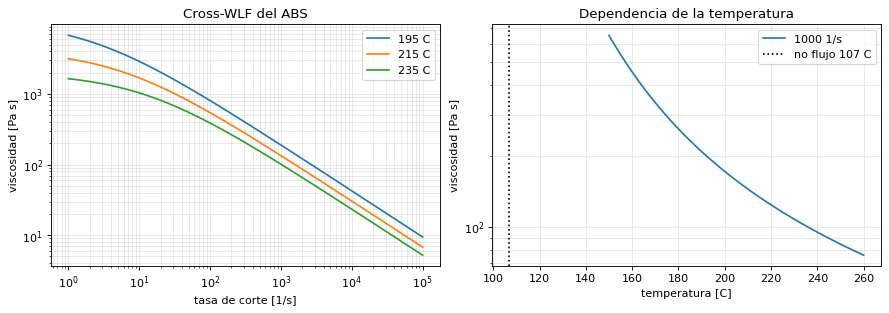

In [2]:
# --- ABS AF312F: Cross-WLF (Cadmould), D3 = 1.6e-7 K/Pa no se usa ---
LAW = CrossWLF(n=0.34514, tau_star=22881.0, D1=2.67853e10, D2=373.15, A1=22.699, A2=51.6, gamma_min=1e-2)
T_MELT, T_MOLD, T_NOFLOW = 215.0, 58.0, 107.0          # fundido, pared del molde y temperatura de no flujo [C]
HTC = 2500.0                                            # contacto fundido-molde durante el llenado [W/m2K]
Q = 16.351e-6                                           # caudal constante de la maquina [m3/s] (caso 002 de Cadmould)

CP_T = [32, 42, 57, 66, 71, 76, 80, 84, 88, 94, 98, 108, 133, 176, 225]
CP_V = [1206, 1263, 1331, 1391, 1431, 1458, 1503, 1561, 1634, 1722, 1754, 1765, 1813, 1892, 1980]
K_T = [39, 57.2, 77.3, 97.3, 117.4, 137, 156.5, 175.4, 194.3, 213.9, 233.9]
K_V = [0.161, 0.159, 0.162, 0.178, 0.18, 0.184, 0.184, 0.185, 0.185, 0.186, 0.188]
b1m, b2m, b5 = 8.39e-4, 5.405e-7, 360.15                # Tait, dominio fundido, a presion cero: v = b1m + b2m (T - b5) [m3/kg, T en K]
RHO = 1.0 / (b1m + b2m * (T_MELT + 273.15 - b5))
CP = float(np.interp(T_MELT, CP_T, CP_V))
K = float(np.interp(T_MELT, K_T, K_V))
print(f'a {T_MELT:.0f} C: densidad {RHO:.0f} kg/m3, calor especifico {CP:.0f} J/kgK, conductividad {K:.3f} W/mK; '
      f'difusividad {K / (RHO * CP) * 1e6:.3f} mm2/s (Cadmould: 0.102 a temperatura ambiente)')
mu0 = float(LAW.zero_shear(T_MELT))
print(f'viscosidad a cero corte {mu0:.0f} Pa s; a 1000 1/s {float(LAW(np.array(1e6), T_MELT)):.0f} Pa s')

rates = np.logspace(0, 5, 100)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
for T in (195.0, 215.0, 235.0):
    axes[0].loglog(rates, np.asarray(LAW(rates ** 2, T)), label=f'{T:.0f} C')
axes[0].set_xlabel('tasa de corte [1/s]'); axes[0].set_ylabel('viscosidad [Pa s]'); axes[0].legend(); axes[0].set_title('Cross-WLF del ABS')
temps = np.linspace(150.0, 260.0, 100)
axes[1].semilogy(temps, np.asarray(LAW(np.full(temps.shape, 1e6), temps)), label='1000 1/s')
axes[1].axvline(T_NOFLOW, ls=':', color='k', label=f'no flujo {T_NOFLOW:.0f} C')
axes[1].set_xlabel('temperatura [C]'); axes[1].set_ylabel('viscosidad [Pa s]'); axes[1].legend(); axes[1].set_title('Dependencia de la temperatura')
for ax in axes:
    ax.grid(True, which='both', alpha=0.3)
plt.show()

## La geometría: de la malla de Cadmould a la doble superficie

El `.cfe` es un archivo de texto: una línea de cabecera (nodos, elementos), los elementos (tres nodos, el espesor local en mm y un indicador; las
líneas de cuatro columnas son los enlaces entre pieles de Cadmould) y las coordenadas de los nodos. Se leen los triángulos y se comprueba que forman
una **superficie cerrada, orientada hacia fuera**, que encierra el volumen real de la pieza (22 040 mm³).

`DualDomain` necesita las **caras del CAD**, que la malla no trae: se recuperan agrupando los triángulos contiguos cuyas normales difieren menos de
25° (las caras planas y suaves salen enteras). Con ellas, `DualDomain` decide qué caras son **pieles** (la cara tiene delante, a un espesor, la
opuesta) y cuáles son **borde** (el canto de las paredes, los bordes de las aperturas), mide el espesor de cada triángulo con un rayo hacia dentro y
une cada nodo con el punto opuesto de la otra piel. Se calcula una vez (más de un minuto) y se guarda en `resultados_vtk/`.

In [3]:
def read_cfe(path):
    with open(path) as f:
        n_nodes, n_elem, _ = map(int, f.readline().split())
        rows = [f.readline().split() for _ in range(n_elem)]
        xyz = np.array([f.readline().split() for _ in range(n_nodes)], dtype=float)
    tri = np.array([r[:4] for r in rows if len(r) == 5], dtype=float)
    return xyz, tri[:, :3].astype(int) - 1, tri[:, 3]


def check_surface(x, t):
    # cerrada y con orientacion consistente: cada arista dirigida aparece una vez y su opuesta tambien; volumen con signo > 0: hacia fuera
    n = len(x)
    e = np.concatenate([t[:, [0, 1]], t[:, [1, 2]], t[:, [2, 0]]])
    fwd, rev = e[:, 0] * n + e[:, 1], e[:, 1] * n + e[:, 0]
    closed = len(np.unique(fwd)) == len(fwd) and bool(np.all(np.isin(rev, fwd)))
    a, b, c = x[t[:, 0]], x[t[:, 1]], x[t[:, 2]]
    return closed, float(np.einsum('ij,ij->i', a, np.cross(b, c)).sum() / 6)


def patches(x, t, angle):
    # caras: componentes de triangulos contiguos con normales a menos de `angle` grados
    n = len(x)
    a, b, c = x[t[:, 0]], x[t[:, 1]], x[t[:, 2]]
    nrm = np.cross(b - a, c - a)
    nrm /= np.linalg.norm(nrm, axis=1, keepdims=True)
    e = np.concatenate([t[:, [0, 1]], t[:, [1, 2]], t[:, [2, 0]]])
    owner = np.tile(np.arange(len(t)), 3)
    fwd, rev = e[:, 0] * n + e[:, 1], e[:, 1] * n + e[:, 0]
    order = np.argsort(fwd)
    other = owner[order][np.searchsorted(fwd[order], rev)]           # el triangulo al otro lado de cada arista
    smooth = np.einsum('ij,ij->i', nrm[owner], nrm[other]) > np.cos(np.radians(angle))
    g = sp.coo_matrix((np.ones(smooth.sum()), (owner[smooth], other[smooth])), shape=(len(t), len(t)))
    return csgraph.connected_components(g, directed=False)[1]


FEATURE_ANGLE = 25.0
xyz_mm, tri, h_cad = read_cfe(CASE_DIR / f'{CASE}.cfe')
closed, vol_mm3 = check_surface(xyz_mm, tri)
print(f'{len(xyz_mm)} nodos, {len(tri)} triangulos; superficie cerrada y consistente: {closed}; volumen que encierra {vol_mm3:.1f} mm3 '
      f'(Cadmould: volumen real 22040 mm3); caja {np.ptp(xyz_mm, axis=0).round(1)} mm')
assert closed and vol_mm3 > 0, 'la superficie debe ser cerrada y estar orientada hacia fuera'
labels = patches(xyz_mm, tri, FEATURE_ANGLE)
print(f'{labels.max() + 1} caras (normales a menos de {FEATURE_ANGLE:.0f} grados)')

dual_file = CACHE / 'carcasa_dual.pkl'
start = time.perf_counter()
if dual_file.exists() and not RECOMPUTE:
    dual = pickle.load(open(dual_file, 'rb'))
else:
    dual = DualDomain(xyz_mm * 1e-3, tri, labels, angle=30.0)           # metros
    pickle.dump(dual, open(dual_file, 'wb'))

conn, X = dual.conn, dual.xyz
cross = np.cross(X[conn[:, 1]] - X[conn[:, 0]], X[conn[:, 2]] - X[conn[:, 0]])
area = 0.5 * np.linalg.norm(cross, axis=1)
unit = cross / (2 * area[:, None])
h_el = dual.thickness
volume_dual = float(np.sum(area * h_el) / 2)
kept = np.flatnonzero(np.isin(labels, dual.skins))                      # los triangulos de piel, en el orden de dual.conn
print(f'doble superficie: {len(dual.skins)} caras de piel y {len(dual.edges)} de borde; {len(conn)} triangulos de piel, {len(X)} nodos; '
      f'{len(dual.link_source)} enlaces entre pieles, {len(dual.unjoined)} nodos sin enlace ({time.perf_counter() - start:.0f} s)')
print(f'espesor de {h_el.min() * 1e3:.2f} a {h_el.max() * 1e3:.2f} mm (mediana {np.median(h_el) * 1e3:.2f}); {dual.measured.mean():.0%} medido con su propio '
      f'rayo; volumen de la cavidad {volume_dual * 1e6:.2f} cm3 (CAD 22.04, malla de Cadmould 22.46)')

11340 nodos, 22740 triangulos; superficie cerrada y consistente: True; volumen que encierra 22040.5 mm3 (Cadmould: volumen real 22040 mm3); caja [ 60.   12.5 150. ] mm
152 caras (normales a menos de 25 grados)
doble superficie: 14 caras de piel y 138 de borde; 20593 triangulos de piel, 11183 nodos; 10833 enlaces entre pieles, 350 nodos sin enlace (0 s)
espesor de 0.87 a 3.92 mm (mediana 2.00); 94% medido con su propio rayo; volumen de la cavidad 21.40 cm3 (CAD 22.04, malla de Cadmould 22.46)


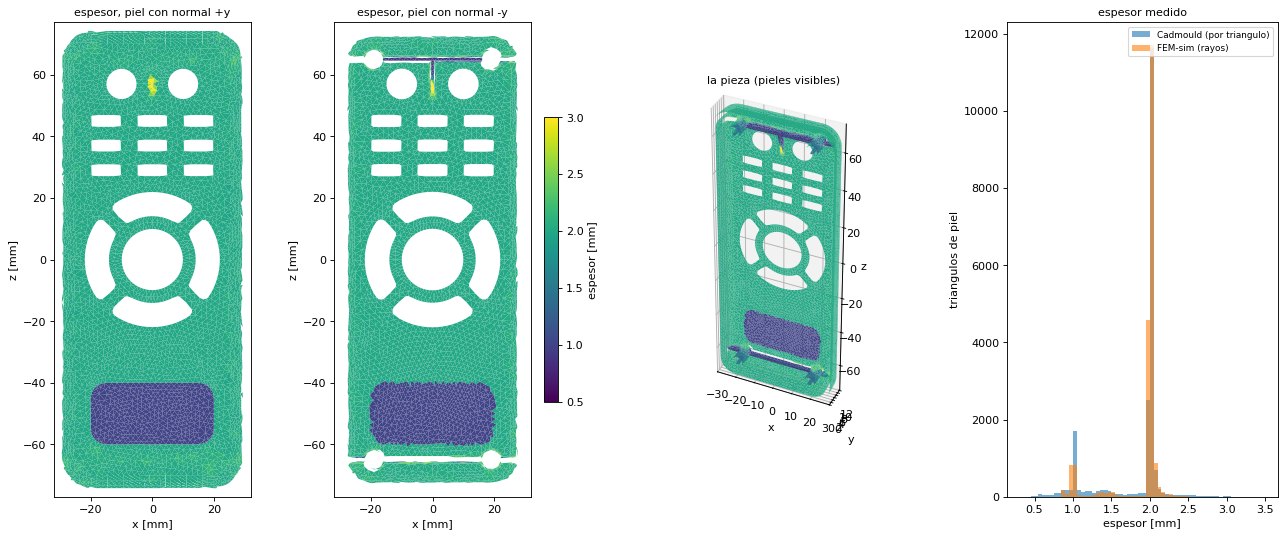

espesor FEM-sim / Cadmould por triangulo: mediana 1.000, entre el percentil 10 y el 90: 1.00 a 1.13


In [4]:
def skin_map(ax, values, side=+1, cmap='viridis', norm=None, title='', contour=None, label=None, lw=0.0):
    # una piel vista desde fuera: los triangulos cuya normal mira a +y (side=+1) o a -y (side=-1), en el plano (x, z), en mm
    sel = np.flatnonzero(unit[:, 1] * side > 0.5)
    v = np.asarray(values, dtype=float)
    per_tri = v if len(v) == len(conn) else v[conn].mean(axis=1)
    verts = X[conn[sel]][:, :, [0, 2]] * 1e3
    pc = PolyCollection(verts, cmap=cmap, norm=norm, edgecolors='face', linewidths=lw)
    pc.set_array(np.ma.masked_invalid(per_tri[sel]))
    ax.add_collection(pc)
    if contour is not None and len(v) == len(X):
        tr = Triangulation(X[:, 0] * 1e3, X[:, 2] * 1e3, conn[sel])
        ax.tricontour(tr, np.nan_to_num(v, nan=0.0), levels=contour, colors='k', linewidths=0.5)
    ax.set_xlim(X[:, 0].min() * 1e3 - 2, X[:, 0].max() * 1e3 + 2); ax.set_ylim(X[:, 2].min() * 1e3 - 2, X[:, 2].max() * 1e3 + 2)
    ax.set_aspect('equal'); ax.set_xlabel('x [mm]'); ax.set_ylabel('z [mm]'); ax.set_title(title, fontsize=10)
    return pc


fig = plt.figure(figsize=(16, 6.6), constrained_layout=True)
gs = fig.add_gridspec(1, 4, width_ratios=[1, 1.15, 1.5, 1.2])
norm_h = plt.Normalize(0.5, 3.0)
ax = fig.add_subplot(gs[0]); skin_map(ax, h_el * 1e3, +1, norm=norm_h, title='espesor, piel con normal +y')
ax = fig.add_subplot(gs[1]); pc = skin_map(ax, h_el * 1e3, -1, norm=norm_h, title='espesor, piel con normal -y')
fig.colorbar(pc, ax=ax, shrink=0.6, label='espesor [mm]')
ax = fig.add_subplot(gs[2], projection='3d')
view = np.array([np.cos(np.radians(35)) * np.cos(np.radians(-65)), np.cos(np.radians(35)) * np.sin(np.radians(-65)), np.sin(np.radians(35))])
vis = unit @ view > 0
pc3 = Poly3DCollection(X[conn[vis]] * 1e3, cmap='viridis', norm=norm_h, linewidths=0.0, edgecolors='none')
pc3.set_array(h_el[vis] * 1e3)
ax.add_collection3d(pc3)
for lim, d in zip((ax.set_xlim, ax.set_ylim, ax.set_zlim), range(3)):
    lim(X[:, d].min() * 1e3, X[:, d].max() * 1e3)
ax.set_box_aspect(np.ptp(X, axis=0)); ax.view_init(35, -65); ax.set_title('la pieza (pieles visibles)', fontsize=10)
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
ax = fig.add_subplot(gs[3])
bins = np.linspace(0.3, 3.5, 65)
ax.hist(h_cad[kept], bins=bins, alpha=0.6, label='Cadmould (por triangulo)')
ax.hist(h_el * 1e3, bins=bins, alpha=0.6, label='FEM-sim (rayos)')
ax.set_xlabel('espesor [mm]'); ax.set_ylabel('triangulos de piel'); ax.legend(fontsize=8); ax.set_title('espesor medido', fontsize=10)
plt.show()
ratio = h_el * 1e3 / h_cad[kept]
print(f'espesor FEM-sim / Cadmould por triangulo: mediana {np.median(ratio):.3f}, entre el percentil 10 y el 90: '
      f'{np.percentile(ratio, 10):.2f} a {np.percentile(ratio, 90):.2f}')

## La entrada y el canal frío

Cadmould pone la entrada en el punto **(29.79, 5.95, −0.16) mm**, sobre la cara exterior de la pared lateral $x = +30$, con la normal casi en
$+x$. Aquí se sitúa el **canal frío** sobre esa normal, como un bebedero recto que sale de la boquilla de la máquina hasta la pared y una entrada
puntual (*pin gate*) que desemboca en el nodo de la piel más próximo. Las dimensiones son un diseño sencillo, no una recomendación:

| tramo | diámetro | longitud |
|---|---|---|
| bebedero (canal frío) | 6 mm | 40 mm |
| entrada puntual | 3 mm | 1.5 mm |

Para el **caso A** (referencia de Cadmould) la entrada es un tubo muy ancho y corto (12 mm × 0.5 mm): su pérdida de presión es despreciable, equivale
a la entrada puntual sin canal que simuló Cadmould.

En la red de alimentación de FEM-sim el fundido del canal está a la temperatura de inyección y **no se congela** (modelo de canal caliente); el
**caso C** estima la capa congelada de un canal frío con la que se forma en la propia cavidad junto a la entrada y estrecha los diámetros.

nodo de la entrada: 7169, a 0.84 mm del punto de Cadmould, espesor local 2.00 mm
volumen del bebedero 1.13 cm3 (5.3% de la cavidad): tarda 0.069 s en llenarse a 16.35 cm3/s


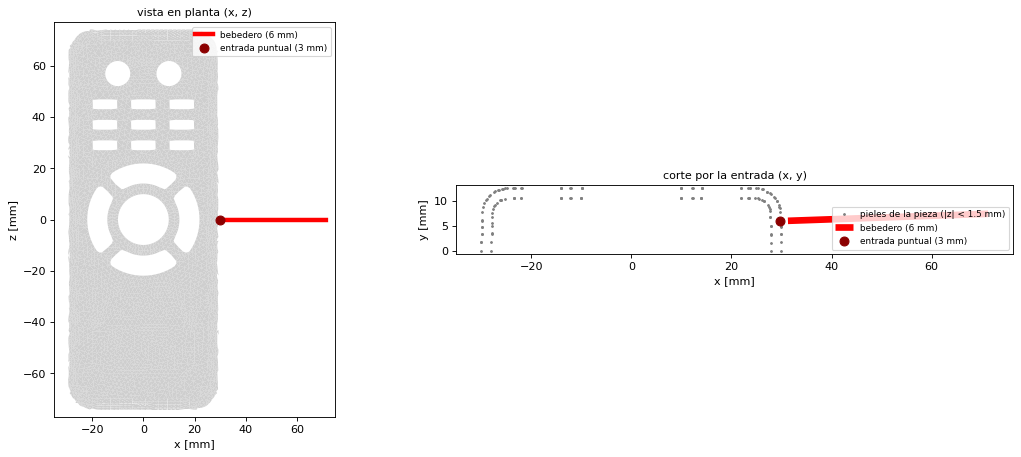

In [5]:
P_INJ = np.array([29.7923, 5.94565, -0.164531]) * 1e-3                 # entrada de Cadmould [m]
NORMAL = np.array([0.999387, 0.0350214, -0.000173944])


def make_runner(d_sprue, d_gate, l_sprue, l_gate, divisions):
    rs = RunnerSystem()
    nozzle = rs.addNode(P_INJ + (l_sprue + l_gate) * NORMAL)             # la boquilla, fuera de la pieza
    end = rs.addSegment(nozzle, P_INJ + l_gate * NORMAL, d_sprue, divisions=divisions)
    rs.addGate(end, tuple(P_INJ), d_gate, l_gate)                        # al nodo de la piel mas proximo
    rs.setInlet(nozzle, Q)
    return rs


PARAMS_A = dict(d_sprue=12e-3, d_gate=12e-3, l_sprue=0.5e-3, l_gate=0.5e-3, divisions=1)      # entrada puntual sin canal
PARAMS_B = dict(d_sprue=6e-3, d_gate=3e-3, l_sprue=40e-3, l_gate=1.5e-3, divisions=8)         # canal frio simple
gate_node = int(np.argmin(np.linalg.norm(X - P_INJ, axis=1)))
V_runner = np.pi / 4 * PARAMS_B['d_sprue'] ** 2 * PARAMS_B['l_sprue']
print(f'nodo de la entrada: {gate_node}, a {np.linalg.norm(X[gate_node] - P_INJ) * 1e3:.2f} mm del punto de Cadmould, espesor local '
      f'{h_el[np.any(conn == gate_node, axis=1)].mean() * 1e3:.2f} mm')
print(f'volumen del bebedero {V_runner * 1e6:.2f} cm3 ({V_runner / volume_dual:.1%} de la cavidad): tarda {V_runner / Q:.3f} s en llenarse a {Q * 1e6:.2f} cm3/s')

rs = make_runner(**PARAMS_B)
line = np.array(rs.xyz) * 1e3
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6), constrained_layout=True, gridspec_kw=dict(width_ratios=[1, 1.3]))
ax = axes[0]
skin_map(ax, np.full(len(X), 1.2), +1, cmap='Greys', norm=plt.Normalize(0, 4), title='vista en planta (x, z)')
ax.plot(line[:, 0], line[:, 2], 'r-', lw=4, label='bebedero (6 mm)')
ax.plot(P_INJ[0] * 1e3, P_INJ[2] * 1e3, 'o', color='darkred', ms=8, label='entrada puntual (3 mm)')
ax.set_xlim(-35, 75); ax.legend(loc='upper right', fontsize=8)
ax = axes[1]
cut = np.abs(X[:, 2] - P_INJ[2]) < 1.5e-3                              # un corte de la pieza por el plano de la entrada
ax.plot(X[cut, 0] * 1e3, X[cut, 1] * 1e3, '.', color='0.5', ms=3, label='pieles de la pieza (|z| < 1.5 mm)')
ax.plot(line[:, 0], line[:, 1], 'r-', lw=PARAMS_B['d_sprue'] * 1e3, solid_capstyle='butt', label='bebedero (6 mm)')
ax.plot(P_INJ[0] * 1e3, P_INJ[1] * 1e3, 'o', color='darkred', ms=8, label='entrada puntual (3 mm)')
ax.set_aspect('equal'); ax.set_xlabel('x [mm]'); ax.set_ylabel('y [mm]'); ax.legend(loc='lower right', fontsize=8); ax.set_title('corte por la entrada (x, y)', fontsize=10)
plt.show()

## Los llenados

`HeleShawFilling.from_dual_domain` (medio espesor por piel y enlaces entre pieles) con `addRunners` (la red de alimentación) y el llenado no isotermo:
el fundido entra a 215 °C en un molde a 58 °C y la capa que baja de 107 °C se congela y estrecha el paso. El caudal de la máquina es constante;
`batch = 0.1` avanza el frente por lotes del 10 % de sus nodos (fase 0).

**Acoplamiento entre pieles.** `from_dual_domain` pone en cada enlace una conductancia de 20 veces la del plano, para que el fundido cruce la pared
y los dos frentes avancen juntos. Con una entrada **puntual** sobre una cara, el primer nodo lleno manda casi todo su caudal a la otra piel por el enlace, y
hasta ahora la tangente de Newton no llevaba la derivada de los enlaces: la presión no convergía y hubo que bajar el acoplamiento a 1. Se corrigió
(`HeleShawFilling._link_tangent`, con prueba frente a diferencias finitas) y aquí se usa el valor por defecto, 20.

**El último paso.** Con caudal constante, los últimos nodos de una cavidad casi llena solo reciben el fundido que sobra y la presión de entrada del
último paso salta (de 32 a 35 MPa en el 0.2 % final), y hay un escalón mayor hacia el 96 %. Cadmould pasa a control por presión desde el 99 %; aquí se
compara la presión y la fuerza de cierre al **95 %** del volumen, antes de esos escalones (el 99 % se muestra también, con esa salvedad).

Cada llenado tarda entre 15 y 25 minutos con la malla completa (11 000 nodos); los resultados se guardan en `resultados_vtk/` y la próxima vez se cargan al momento. En cada paso se
guardan el nivel de llenado, la presión de entrada y la **fuerza de cierre** en x, y, z (presión de cada triángulo por su área proyectada; las
dos pieles cuentan una vez).

In [6]:
COUPLING, CELLS, BATCH = 20.0, 16, 0.1
LEVELS = np.arange(0.1, 1.001, 0.1)
V_CAV = volume_dual


def run_case(name, params):
    sig = repr((name, sorted(params.items()), COUPLING, CELLS, BATCH, Q, T_MELT, T_MOLD, HTC, T_NOFLOW, RHO, CP, K, len(X)))
    cache = CACHE / f'carcasa_{name}.pkl'
    if cache.exists() and not RECOMPUTE:
        out = pickle.load(open(cache, 'rb'))
        if out['sig'] == sig:
            print(f'caso {name}: cargado de {cache} ({out["wall"]:.0f} s de calculo)')
            return out
    fill = HeleShawFilling.from_dual_domain(dual, LAW, T=T_MELT, coupling=COUPLING)
    fill.setThermal(T_MELT, T_MOLD, RHO, CP, K, htc=HTC, T_noflow=T_NOFLOW, cells=CELLS)
    rs = make_runner(**params)
    fill.addRunners(rs)
    series, snaps = [], {}
    front_T = np.full(len(X), np.nan)

    def on_step(f):
        level = float(f.fill_factor @ f.volume / f.volume.sum())
        pe = f.p[conn].mean(axis=1)
        series.append((f.time, level, f.runners.p[f.runners.inlet[0]], f.p[gate_node],
                       *[float(pe @ (area * np.abs(unit[:, d])) / 2) for d in range(3)]))
        new = (f.fill_factor >= 1.0) & np.isnan(front_T)
        if np.any(new):
            front_T[new] = f.mean_temperature()[new]
        for lv in LEVELS:
            if level >= lv - 1e-9 and lv not in snaps:
                snaps[lv] = dict(t=f.time, p=f.p.copy(), T=f.mean_temperature(), frozen=f.frozen_fraction(), fill=f.fill_factor.copy())

    start = time.perf_counter()
    fill.fill(progress=True, every=50, batch=BATCH, on_step=on_step)
    wall = time.perf_counter() - start
    out = dict(sig=sig, name=name, params=params, series=np.array(series), history=np.array(fill.history), fill_time=fill.fill_time.copy(),
               frozen=fill.frozen_fraction(), T=fill.mean_temperature(), front_T=front_T, snaps=snaps, wall=wall, short_shot=fill.short_shot,
               time=fill.time, net_xyz=np.array(rs.xyz), net_p=fill.runners.p.copy(), gate_p_cavity=float(fill.p[gate_node]),
               tube_L=rs.tube_L.copy(), tube_d=rs.tube_d.copy(), tube_a=rs.tube_a.copy(), tube_b=rs.tube_b.copy(), tube_gate=rs.tube_gate.copy(),
               gate_cavity=rs.gate_cavity.copy(), volume=float(fill.volume.sum()))
    pickle.dump(out, open(cache, 'wb'))
    print(f'caso {name}: {wall:.0f} s de calculo, llena a {fill.time:.3f} s' + (f', TIRO CORTO a {fill.short_shot:.3f} s' if fill.short_shot else ''))
    return out


def level_value(out, col, lv):
    # una columna de la serie (2: presion de entrada, 3: presion en el nodo de la entrada, 4-6: fuerza de cierre x, y, z) al nivel de llenado lv
    s = out['series']
    return float(np.interp(lv, s[:, 1], s[:, col]))

### Caso A: entrada puntual sin canal (la referencia de Cadmould)

In [7]:
A = run_case('A', PARAMS_A)
sA = A['series']
print(f'al 95 %: presion de entrada {level_value(A, 2, 0.95) / 1e6:.2f} MPa (Cadmould: 27.47 MPa); fuerza de cierre '
      f'x {level_value(A, 4, 0.95) / 1e3:.1f}, y {level_value(A, 5, 0.95) / 1e3:.1f}, z {level_value(A, 6, 0.95) / 1e3:.1f} kN (Cadmould: 31.3, 72.4, 4.4 kN); '
      f'capa congelada media al final {A["frozen"].mean():.1%}')

   llenado: paso 50, t = 0.0379 s, 2.3 % de los nodos llenos, p de entrada 1.584 MPa, 7 it. de Newton (38 s)
   llenado: paso 100, t = 0.08426 s, 5.7 % de los nodos llenos, p de entrada 3.161 MPa, 7 it. de Newton (78 s)
   llenado: paso 150, t = 0.1559 s, 10.3 % de los nodos llenos, p de entrada 4.767 MPa, 6 it. de Newton (123 s)
   llenado: paso 200, t = 0.244 s, 16.6 % de los nodos llenos, p de entrada 6.365 MPa, 7 it. de Newton (176 s)
   llenado: paso 250, t = 0.337 s, 23.6 % de los nodos llenos, p de entrada 7.971 MPa, 7 it. de Newton (228 s)
   llenado: paso 300, t = 0.4648 s, 33.1 % de los nodos llenos, p de entrada 9.94 MPa, 7 it. de Newton (509 s)
   llenado: paso 350, t = 0.6207 s, 45.0 % de los nodos llenos, p de entrada 12.16 MPa, 7 it. de Newton (600 s)
   llenado: paso 400, t = 0.8322 s, 62.1 % de los nodos llenos, p de entrada 14.57 MPa, 7 it. de Newton (713 s)
   llenado: paso 450, t = 1.054 s, 79.0 % de los nodos llenos, p de entrada 17.27 MPa, 11 it. de Newton (896 s)

### Caso B: con el canal frío (bebedero de 6 mm y entrada de 3 mm, sin capa congelada)

In [8]:
B = run_case('B', PARAMS_B)
sB = B['series']
print(f'presion de entrada al 99 %: {level_value(B, 2, 0.99) / 1e6:.2f} MPa (sin canal {level_value(A, 2, 0.99) / 1e6:.2f}); la cavidad se llena a '
      f'{B["time"]:.3f} s (sin canal {A["time"]:.3f} s; el bebedero tarda {V_runner / Q:.3f} s en llenarse)')

   llenado: paso 50, t = 0.09477 s, 1.9 % de los nodos llenos, p de entrada 5.643 MPa, 8 it. de Newton (45 s)
   llenado: paso 100, t = 0.14 s, 5.2 % de los nodos llenos, p de entrada 7.207 MPa, 7 it. de Newton (89 s)
   llenado: paso 150, t = 0.2076 s, 9.5 % de los nodos llenos, p de entrada 8.789 MPa, 8 it. de Newton (139 s)
   llenado: paso 200, t = 0.2934 s, 15.6 % de los nodos llenos, p de entrada 10.42 MPa, 7 it. de Newton (197 s)
   llenado: paso 250, t = 0.3847 s, 22.6 % de los nodos llenos, p de entrada 11.98 MPa, 6 it. de Newton (255 s)
   llenado: paso 300, t = 0.5069 s, 31.6 % de los nodos llenos, p de entrada 13.9 MPa, 9 it. de Newton (505 s)
   llenado: paso 350, t = 0.6595 s, 43.2 % de los nodos llenos, p de entrada 16.09 MPa, 7 it. de Newton (584 s)
   llenado: paso 400, t = 0.8643 s, 59.4 % de los nodos llenos, p de entrada 18.48 MPa, 8 it. de Newton (681 s)
   llenado: paso 450, t = 1.094 s, 77.0 % de los nodos llenos, p de entrada 21.18 MPa, 8 it. de Newton (829 s)
 

### Caso C: el mismo canal con su capa congelada

El fundido del canal se enfría contra la pared de acero igual que el de la cavidad. Como estimación se toma la **capa congelada que el propio
modelo calcula en la cavidad junto a la entrada** (a menos de 15 mm), al final del caso A, y se resta dos veces (una por pared) a los diámetros del
bebedero y de la entrada. Es una cota gruesa (el bebedero tiene más volumen y menos corte que una pared de 2 mm), no el cálculo de la capa en el
canal, que es el trabajo pendiente de la fase 2b.

In [9]:
near = np.linalg.norm(X - X[gate_node], axis=1) < 15e-3
h_gate = h_el[np.any(near[conn], axis=1)].mean()
f_gate = A['frozen'][near].mean()
delta = f_gate * h_gate / 2                  # espesor congelado por pared
print(f'junto a la entrada (<15 mm): espesor {h_gate * 1e3:.2f} mm, capa congelada {f_gate:.1%} del semiespesor, es decir {delta * 1e3:.3f} mm por pared')
PARAMS_C = dict(PARAMS_B, d_sprue=PARAMS_B['d_sprue'] - 2 * delta, d_gate=PARAMS_B['d_gate'] - 2 * delta)
print(f'diametros efectivos: bebedero {PARAMS_C["d_sprue"] * 1e3:.2f} mm, entrada {PARAMS_C["d_gate"] * 1e3:.2f} mm')
C = run_case('C', PARAMS_C)
sC = C['series']
print(f'presion de entrada al 99 %: {level_value(C, 2, 0.99) / 1e6:.2f} MPa (canal sin capa {level_value(B, 2, 0.99) / 1e6:.2f}, '
      f'sin canal {level_value(A, 2, 0.99) / 1e6:.2f})')

junto a la entrada (<15 mm): espesor 2.01 mm, capa congelada 3.2% del semiespesor, es decir 0.033 mm por pared
diametros efectivos: bebedero 5.93 mm, entrada 2.93 mm
   llenado: paso 50, t = 0.09337 s, 1.9 % de los nodos llenos, p de entrada 5.756 MPa, 8 it. de Newton (37 s)
   llenado: paso 100, t = 0.1386 s, 5.2 % de los nodos llenos, p de entrada 7.32 MPa, 7 it. de Newton (72 s)
   llenado: paso 150, t = 0.2062 s, 9.5 % de los nodos llenos, p de entrada 8.902 MPa, 8 it. de Newton (111 s)
   llenado: paso 200, t = 0.292 s, 15.6 % de los nodos llenos, p de entrada 10.53 MPa, 7 it. de Newton (156 s)
   llenado: paso 250, t = 0.3833 s, 22.6 % de los nodos llenos, p de entrada 12.09 MPa, 6 it. de Newton (203 s)
   llenado: paso 300, t = 0.5055 s, 31.6 % de los nodos llenos, p de entrada 14.01 MPa, 9 it. de Newton (421 s)
   llenado: paso 350, t = 0.6581 s, 43.2 % de los nodos llenos, p de entrada 16.2 MPa, 7 it. de Newton (488 s)
   llenado: paso 400, t = 0.8629 s, 59.4 % de los nodos ll

## Patrón de llenado

Tiempo en que llega el fundido a cada punto del caso A, en las dos pieles; las líneas negras son **isócronas** (posiciones del frente cada 0.1 s). La
entrada está en la pared lateral derecha ($x = +30$ mm), a media altura de la pieza ($z = 0$): el fundido sube por la pared hacia las dos pieles y
recorre la tapa hasta el lado opuesto. Abajo, los puntos que se llenan los últimos (el 3 % final del tiempo): ahí queda el aire, y necesitan
venteo (los bordes de la pieza y de las aperturas ventean por el plano de partición; un punto en el interior de la cara, no).

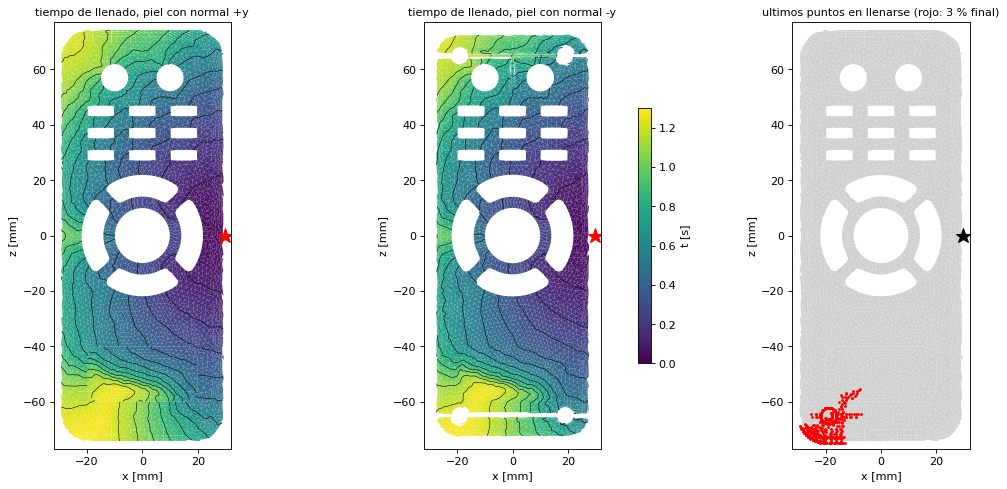

el fundido llega a la entrada a 0.002 s y llena el ultimo nodo a 1.302 s; 440 nodos en el 3 % final, a z entre -75 y -55 mm y x entre -29 y -7 mm


In [10]:
ft = A['fill_time']
fig, axes = plt.subplots(1, 3, figsize=(15, 6.0), constrained_layout=True)
norm_t = plt.Normalize(0, np.nanmax(ft))
levels = np.arange(0.1, np.nanmax(ft), 0.1)
for ax, side in zip(axes[:2], (+1, -1)):
    pc = skin_map(ax, ft, side, cmap='viridis', norm=norm_t, title=f'tiempo de llenado, piel con normal {"+" if side > 0 else "-"}y', contour=levels)
    ax.plot(P_INJ[0] * 1e3, P_INJ[2] * 1e3, 'r*', ms=14)
fig.colorbar(pc, ax=axes[:2], shrink=0.6, label='t [s]')
ax = axes[2]
skin_map(ax, np.full(len(X), 1.2), +1, cmap='Greys', norm=plt.Normalize(0, 4), title='ultimos puntos en llenarse (rojo: 3 % final)')
late = ft > 0.97 * np.nanmax(ft)
ax.plot(X[late, 0] * 1e3, X[late, 2] * 1e3, '.', color='r', ms=3)
ax.plot(P_INJ[0] * 1e3, P_INJ[2] * 1e3, 'k*', ms=14)
plt.show()
print(f'el fundido llega a la entrada a {np.nanmin(ft):.3f} s y llena el ultimo nodo a {np.nanmax(ft):.3f} s; '
      f'{late.sum()} nodos en el 3 % final, a z entre {X[late, 2].min() * 1e3:.0f} y {X[late, 2].max() * 1e3:.0f} mm y x entre {X[late, 0].min() * 1e3:.0f} y {X[late, 0].max() * 1e3:.0f} mm')

## Presión de inyección y fuerza de cierre, frente a Cadmould

La presión de entrada crece con el recorrido del fundido y la capa congelada. La curva de Cadmould (caso `002`, sin canal) se lee del
`_Result_Summary.txt`; la comparación es contra el nivel de llenado (la fracción de volumen), que no depende de que los volúmenes difieran un 3 %.
La **fuerza de cierre** en cada dirección es la presión de la cavidad por su área proyectada.

In [ ]:
def read_cadmould_filling(path):
    rows, started = [], False
    for line in path.read_text(encoding='cp1252').splitlines():
        s = line.strip()
        if s == 'Llenado':
            started = True
            continue
        if started and s.lower().startswith('pospresi'):
            break
        parts = s.split()
        if started and len(parts) == 7:
            try:
                rows.append([float(v) for v in parts])
            except ValueError:
                pass
    return np.array(rows)                       # t [s], nivel [%], caudal [cm3/s], p [bar], Fx, Fy, Fz [kN]


cad = read_cadmould_filling(CASE_DIR / f'{CASE}_Result_Summary.txt')
cad_level, cad_p, cad_F = cad[:, 1] / 100, cad[:, 3] / 10, cad[:, 4:7]
print(f'Cadmould: {len(cad)} filas, de {cad[0, 0]:.3f} a {cad[-1, 0]:.3f} s, presion final {cad_p[-1]:.2f} MPa, fuerza de cierre final {cad_F[-1].round(1)} kN')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), constrained_layout=True)
ax = axes[0]
ax.plot(cad_level * 100, cad_p, 'k-', lw=2, label='Cadmould (sin canal)')
for s, lab, st in ((sA, 'A: sin canal', 'C0-'), (sB, 'B: canal frio', 'C1-'), (sC, 'C: canal con capa congelada', 'C3-')):
    ax.plot(s[:, 1] * 100, s[:, 2] / 1e6, st, label=lab)
ax.set_xlabel('nivel de llenado [%]'); ax.set_ylabel('presion de entrada [MPa]'); ax.grid(True); ax.legend(fontsize=8); ax.set_title('Presion de entrada')
ax = axes[1]
for d, name, col in ((1, 'y', 'C0'), (0, 'x', 'C2'), (2, 'z', 'C4')):
    ax.plot(cad_level * 100, cad_F[:, d], '--', color=col, lw=2, label=f'Cadmould {name}')
    ax.plot(sA[:, 1] * 100, sA[:, 4 + d] / 1e3, '-', color=col, label=f'FEM-sim A, {name}')
ax.set_xlabel('nivel de llenado [%]'); ax.set_ylabel('fuerza de cierre [kN]'); ax.grid(True); ax.legend(fontsize=8, ncol=2); ax.set_title('Fuerza de cierre (caso A)')
ax = axes[2]
lv = np.linspace(0.05, 0.99, 60)
ratio_p = np.interp(lv, sA[:, 1], sA[:, 2] / 1e6) / np.interp(lv, cad_level, cad_p)
ax.plot(lv * 100, ratio_p, 'C0-', label='presion')
ratio_f = np.interp(lv, sA[:, 1], sA[:, 5] / 1e3) / np.interp(lv, cad_level, cad_F[:, 1])
ax.plot(lv * 100, ratio_f, 'C1-', label='fuerza de cierre y')
ax.axhline(1.0, color='k', ls=':')
ax.set_xlabel('nivel de llenado [%]'); ax.set_ylabel('FEM-sim A / Cadmould'); ax.grid(True); ax.legend(fontsize=8); ax.set_ylim(0, 2.2); ax.set_title('Cociente')
plt.show()

rows = []
for lv_ in (0.25, 0.5, 0.75, 0.95, 0.99):
    pc_ = np.interp(lv_, cad_level, cad_p)
    rows.append((lv_, pc_, *[np.interp(lv_, s[:, 1], s[:, 2] / 1e6) for s in (sA, sB, sC)]))
print('presion de entrada [MPa] segun el nivel de llenado')
print('nivel    Cadmould   A (sin canal)   B (canal)   C (canal+capa)   A/Cadmould')
for r in rows:
    print(f'{r[0]:5.0%}   {r[1]:8.2f}   {r[2]:12.2f}   {r[3]:9.2f}   {r[4]:13.2f}   {r[2] / r[1]:9.2f}')

## El canal frío: dónde se gasta la presión

Con el caudal constante, la presión de la boquilla se reparte entre el bebedero, la entrada puntual y la cavidad. A la izquierda, la presión de
la boquilla y la del nodo de la entrada (en la cavidad) durante el llenado; a la derecha, su reparto al 95 % del llenado, con la caída de cada
tubo calculada aparte con la fluidez exacta del tubo (Cross–WLF a 215 °C, el caudal de la máquina) y que debe coincidir con la diferencia entre la
presión de la boquilla y la de la cavidad. La entrada (3 mm de diámetro, 1.5 mm de largo) es corta pero estrecha, con un corte de miles de 1/s; el
bebedero, más largo (40 mm), pierde casi todo.

In [ ]:
from scipy.optimize import brentq
from Source.Physics.Runners import TubeFluidity

tube = TubeFluidity(LAW, T_MELT)


def tube_drop(D, L):
    # caida de presion de un tubo de diametro D y largo L por el que pasa el caudal Q: q(G) = S(R, G) G = Q
    f = lambda lg: float(tube(0.5 * D, np.exp(lg)) * np.exp(lg)) - Q
    return float(np.exp(brentq(f, np.log(1e-3), np.log(1e12))) * L)


fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), constrained_layout=True)
ax = axes[0]
for out, lab, col in ((A, 'A', 'C0'), (B, 'B', 'C1'), (C, 'C', 'C3')):
    s = out['series']
    ax.plot(s[:, 1] * 100, s[:, 2] / 1e6, '-', color=col, label=f'{lab}: boquilla')
    ax.plot(s[:, 1] * 100, s[:, 3] / 1e6, '--', color=col, label=f'{lab}: nodo de la entrada')
ax.set_xlabel('nivel de llenado [%]'); ax.set_ylabel('presion [MPa]'); ax.grid(True); ax.legend(fontsize=8, ncol=2); ax.set_xlim(0, 100)
ax.set_title('Presion de la boquilla y de la cavidad')
ax = axes[1]
names, parts = ['A sin canal', 'B canal', 'C canal + capa'], []
for out in (A, B, C):
    p = out['params']
    parts.append(dict(sprue=tube_drop(p['d_sprue'], p['l_sprue']), gate=tube_drop(p['d_gate'], p['l_gate']),
                      cavity=level_value(out, 3, 0.95), total=level_value(out, 2, 0.95)))
bottom = np.zeros(3)
for key, lab, col in (('sprue', 'bebedero', 'C1'), ('gate', 'entrada', 'C3'), ('cavity', 'cavidad (en el nodo de la entrada)', 'C0')):
    vals = np.array([q[key] for q in parts]) / 1e6
    ax.bar(names, vals, bottom=bottom, label=lab, color=col)
    bottom += vals
ax.set_ylabel('presion de la boquilla [MPa]'); ax.legend(fontsize=8); ax.set_title('Reparto de la presion al 95 % del llenado')
plt.show()
for n_, q in zip(names, parts):
    print(f"{n_:16s} boquilla {q['total'] / 1e6:6.2f} MPa (simulada); bebedero {q['sprue'] / 1e6:5.2f} + entrada {q['gate'] / 1e6:5.2f} + cavidad {q['cavity'] / 1e6:6.2f} "
          f"= {sum(q[k] for k in ('sprue', 'gate', 'cavity')) / 1e6:6.2f} MPa")

### Sensibilidad a la capa congelada del canal

Con el caudal fijo, en un tubo de ley de potencia la caída de presión crece como $D^{-(3n+1)}$ ($n = 0.35$: casi como $D^{-2}$), así que adelgazar el
canal con una capa congelada cuesta menos presión de lo que parece. La curva da la caída del bebedero y la entrada juntos en función del espesor
congelado por pared $\delta$. Se marcan el $\delta$ del caso C (la capa que calcula el modelo en la cavidad) y una **cota con contacto perfecto**: el
espesor que baja de la temperatura de no flujo en un sólido semiinfinito con la pared a la temperatura del molde,
$\delta = 2\sqrt{\alpha t}\,\mathrm{erf}^{-1}\!\big[(T_\text{nf} - T_\text{molde})/(T_\text{fundido} - T_\text{molde})\big]$, que desprecia la resistencia de contacto y el calor
que trae el fundido (el contacto real de 2500 W/m²K y el calentamiento viscoso la reducen).

In [ ]:
from scipy.special import erfinv

deltas = np.linspace(0.0, 0.5e-3, 26)
drops = np.array([tube_drop(PARAMS_B['d_sprue'] - 2 * d, PARAMS_B['l_sprue']) + tube_drop(PARAMS_B['d_gate'] - 2 * d, PARAMS_B['l_gate']) for d in deltas]) / 1e6
alpha = K / (RHO * CP)
d_cond = 2 * np.sqrt(alpha * C['time']) * erfinv((T_NOFLOW - T_MOLD) / (T_MELT - T_MOLD))
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.plot(deltas * 1e3, drops, 'k-')
ax.axvline(delta * 1e3, color='C3', ls='--', label=f'caso C: {delta * 1e3:.3f} mm (capa calculada en la cavidad)')
ax.axvline(d_cond * 1e3, color='C2', ls=':', label=f'cota con contacto perfecto: {d_cond * 1e3:.2f} mm')
ax.set_xlabel('espesor congelado por pared [mm]'); ax.set_ylabel('caida del bebedero + entrada [MPa]'); ax.grid(True); ax.legend(fontsize=8)
ax.set_title('Caida de presion del canal frio frente a su capa congelada')
plt.show()
d0 = drops[0]
for d_ in (delta, 0.1e-3, d_cond, 0.3e-3, 0.5e-3):
    v = tube_drop(PARAMS_B['d_sprue'] - 2 * d_, PARAMS_B['l_sprue']) + tube_drop(PARAMS_B['d_gate'] - 2 * d_, PARAMS_B['l_gate'])
    print(f'capa de {d_ * 1e3:.3f} mm por pared: caida del canal {v / 1e6:.2f} MPa ({v / 1e6 - d0:+.2f} MPa respecto al canal sin capa)')

## Temperatura y capa congelada

A la izquierda, la fracción del espesor congelada al final del llenado (caso A). A la derecha, la temperatura media del espesor del fundido en el
momento en que **llega el frente** a cada nodo, que se compara con la de Cadmould (en su caso `002`, entre 183.2 y 215.7 °C «al pasar»).

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5), constrained_layout=True)
pc = skin_map(axes[0], A['frozen'], +1, cmap='Blues', norm=plt.Normalize(0, 1), title='fraccion congelada al final, piel +y')
fig.colorbar(pc, ax=axes[0], shrink=0.6)
pc = skin_map(axes[1], A['front_T'], +1, cmap='coolwarm', norm=plt.Normalize(T_NOFLOW + 70, T_MELT), title='temperatura media del frente [C], piel +y')
fig.colorbar(pc, ax=axes[1], shrink=0.6)
ax = axes[2]
ax.hist(A['front_T'][np.isfinite(A['front_T'])], bins=40)
lo, hi = np.nanmin(A['front_T']), np.nanmax(A['front_T'])
ax.axvspan(183.2, 215.7, color='gray', alpha=0.25, label='Cadmould: 183.2 a 215.7 C')
ax.set_xlabel('temperatura media al llegar el frente [C]'); ax.set_ylabel('nodos'); ax.legend(); ax.set_title('Temperatura del frente')
plt.show()
print(f'temperatura media del frente al llegar: de {lo:.1f} a {hi:.1f} C (percentil 1: {np.nanpercentile(A["front_T"], 1):.1f}); '
      f'capa congelada media al final {A["frozen"].mean():.1%}, maxima {A["frozen"].max():.1%}')

## Resumen

In [ ]:
def at(out, lv_):
    return np.interp(lv_, out['series'][:, 1], out['series'][:, 2]) / 1e6


F95 = [level_value(o, 4 + d, 0.95) / 1e3 for o in (A, B, C) for d in range(3)]
rows = [('tiempo de llenado de la cavidad [s]', '1.374 (22.4 cm3)', *[f"{o['time']:.3f} (21.4 cm3)" for o in (A, B, C)]),
        ('presion de entrada al 50 % [MPa]', f'{np.interp(0.5, cad_level, cad_p):.1f}', *[f'{at(o, 0.5):.1f}' for o in (A, B, C)]),
        ('presion de entrada al 95 % [MPa]', f'{np.interp(0.95, cad_level, cad_p):.1f}', *[f'{at(o, 0.95):.1f}' for o in (A, B, C)]),
        ('presion de entrada al 99 % [MPa]', f'{np.interp(0.99, cad_level, cad_p):.1f}', *[f'{at(o, 0.99):.1f}' for o in (A, B, C)]),
        ('fuerza de cierre y al 95 % [kN]', f'{np.interp(0.95, cad_level, cad_F[:, 1]):.1f}', *[f'{F95[3 * i + 1]:.1f}' for i in range(3)]),
        ('fuerza de cierre x / z al 95 % [kN]', f'{np.interp(0.95, cad_level, cad_F[:, 0]):.1f} / {np.interp(0.95, cad_level, cad_F[:, 2]):.1f}',
         *[f'{F95[3 * i]:.1f} / {F95[3 * i + 2]:.1f}' for i in range(3)]),
        ('capa congelada media al final', '', *[f"{o['frozen'].mean():.1%}" for o in (A, B, C)]),
        ('tiro corto', 'no', *[('si' if o['short_shot'] else 'no') for o in (A, B, C)]),
        ('tiempo de calculo [s]', '', *[f"{o['wall']:.0f}" for o in (A, B, C)])]
print(f"{'':40s}{'Cadmould':>20s}{'A sin canal':>20s}{'B canal':>20s}{'C canal+capa':>20s}")
for r in rows:
    print(f'{r[0]:40s}' + ''.join(f'{v:>20s}' for v in r[1:]))

## Conclusiones

Con los números de la tabla anterior (malla de Cadmould, 11 183 nodos de piel; ABS AF312F a 215 °C en un molde a 58 °C; 16.35 cm³/s; acoplamiento entre pieles 20):

1. **La geometría llega bien.** La superficie de Cadmould es cerrada y encierra 22 040.5 mm³ (22 040 de Cadmould). `DualDomain` la separa en 14 caras de piel
   y 138 de borde, mide el espesor de 20 593 triángulos (94 % con su propio rayo) y encuentra 10 833 enlaces entre pieles (350 nodos sin enlace, el 3 %).
   El espesor medido coincide con el que trae Cadmould por triángulo (mediana del cociente 1.000, entre 1.00 y 1.13 del percentil 10 al 90). El volumen de la
   cavidad sale un 2.9 % menor (21.40 frente a 22.04 cm³): las caras de borde (el canto de las paredes y de las aperturas) no llevan volumen en el modelo.
2. **Sin canal, el llenado sigue a Cadmould con un error sistemático.** El tiempo por volumen es el mismo (0.0608 frente a 0.0613 s/cm³). La presión de entrada
   queda por debajo: 0.85, 0.81, 0.78 y 0.78 de la de Cadmould al 25, 50, 75 y 95 % del llenado (7.8 / 12.6 / 16.2 / 21.4 MPa frente a 9.2 / 15.4 / 20.9 / 27.5 MPa).
   La fuerza de cierre en y es de 0.70 a 0.75 de la suya en todo el llenado, y la de x de 0.72 a 0.77 hasta el 75 % (0.91 a 0.96 después); la z, muy pequeña
   (menos de 6 kN), no sigue (de 0.14 a 1.28). La temperatura media del frente va de 179.6 a 215.1 °C (Cadmould: 183.2 a 215.7 °C), con el mínimo en el
   compartimento de 1 mm. La dependencia de la viscosidad con la presión ($D_3$), que el módulo no usa, explica solo una parte de la presión baja: a 20 MPa
   sube la viscosidad a bajo corte cerca de un 14 % y, a la tasa de corte del llenado ($\eta \propto \mu_0^{\,n}$), cerca de un 5 %, es decir, como mucho una
   cuarta parte de la diferencia. El resto no se ha aislado (podría ser el acoplamiento entre pieles, los volúmenes de control o el espesor de las zonas de unión).
   Pasar el acoplamiento de 1 a 20 baja la presión solo un 2 % (21.8 a 21.4 MPa al 95 %).
3. **El patrón de llenado es plausible.** El fundido entra por la pared lateral derecha a media altura, sube hacia las dos pieles y recorre la tapa; el
   compartimento de 1 mm del extremo inferior se llena tarde y el último 3 % está en el extremo inferior izquierdo (z entre −75 y −55 mm, x entre −29 y −7 mm).
   No hay un mapa de llenado de Cadmould con que compararlo (los archivos `.saw` y `.car` son binarios), así que no se verificó el patrón, solo la presión,
   la fuerza de cierre y la temperatura.
4. **El canal frío cuesta una presión constante.** Añadir el bebedero de 6 mm × 40 mm y la entrada de 3 mm × 1.5 mm sube la presión de la boquilla en 4.26 MPa durante
   todo el llenado (al 25, 50, 75 y 95 %); la suma de las caídas exactas de los dos tubos, 3.69 + 0.59 = 4.28 MPa, coincide con ella al 0.6 %. La cavidad
   termina 0.064 s más tarde (1.366 frente a 1.302 s): el bebedero, de 1.13 cm³, tarda 0.069 s en llenarse. La fuerza de cierre de la pieza no cambia (la
   presión del canal no empuja sobre la pieza) y el canal no provoca tiro corto.
5. **Su capa congelada es poco importante en este caso.** El modelo calcula en la cavidad junto a la entrada una capa de solo 0.033 mm por pared (el 3 % del
   semiespesor; contacto de 2500 W/m²K y 1.3 s de llenado), que estrecha el canal a 5.93 y 2.93 mm y sube la presión 0.1 MPa. Incluso con la cota de
   contacto perfecto (0.19 mm por pared) la subida es de 0.7 MPa, y con 0.5 mm, de 2.5 MPa: el efecto del canal viene de su geometría, no de su
   congelación, y por eso la fase 2b (capa congelada en el radio) puede esperar. Esto vale para un fundido a 215 °C y un llenado de 1.4 s; un llenado largo
   o un molde más frío lo cambiarían.

**Limitaciones y lo que no se verificó.**

- **Newton con acoplamiento 20.** La entrada puntual en una cara ya converge desde el primer paso (la tangente lleva ahora la derivada de los enlaces, y 6 a 8
  iteraciones por paso son lo habitual). Pero 35 de los 610 pasos del caso A (42 de 617 en B) agotan las 50 iteraciones sin bajar el residuo: cuatro seguidos hacia el
  33 % del llenado y el resto después del 86 %. La presión que dejan es suave, sin saltos que lo delaten, pero no está resuelta a la tolerancia pedida, y esos
  pasos hacen el cálculo mucho más lento (unos 65 minutos por llenado, frente a unos 18 con acoplamiento 1, aunque esa medida coincidió con una suite de pruebas
  corriendo en la misma máquina). No se ha encontrado la causa: la tangente de los enlaces coincide con diferencias finitas a 1e-6 en una tira, con y sin temperatura.
- **Escalón de presión al 96 %.** En A, B y C la presión sube 5.6 MPa en 0.7 ms al 96.4 % del llenado, y otro escalón menor (1.4 MPa) hacia el 99.9 %. En ese
  paso se llenan nodos de los dos extremos de la pieza, así que lo más probable es que acabe un frente y todo el caudal pase al otro, pero no se comprobó. La curva de
  Cadmould es suave (y pasa a control por presión al 99 %): la coincidencia de presiones al 99 % no es un acuerdo, sino ese salto.
- **Una sola configuración.** No hay empaque, enfriamiento ni alabeo; el canal frío se simplificó a tubos rectos (sin codos, conos ni pozo frío); y de Cadmould solo se
  comparó su caso con entrada puntual lateral y caudal constante, no el de caudal por perfil (`006`) ni el del extremo inferior (`001`).
- **La geometría viene de la malla de Cadmould,** no del CAD de SolidWorks (`.SLDPRT`): si se exporta a STEP se puede repetir con `DualDomain.from_step(...)`
  y comparar las dos mallas.

**Siguientes pasos.** (1) Encontrar por qué Newton se atasca con acoplamiento 20 en esos pasos (el residuo se queda en 3e-5, mayor que el caudal, con el paso de línea
sin avanzar); (2) incluir $D_3$ en la viscosidad del módulo y ver cuánto cierra la brecha de presión; (3) exportar la pieza a STEP y comparar;
(4) repetir con los casos `001` (entrada en el extremo) y `006` (caudal por perfil) de Cadmould; (5) empaque a través del canal frío y la fase 2b si se quiere
estudiar un llenado largo o un molde frío.